- title: "Functional diversity and invasion success"
- Author: "Roohullah Amin"
- date: "2026-01-22"
- output: pdf_document

In [1]:
setwd = "Desktop/Environmental change/Lab/Ex_05"

## 1. Downloading & Loading libraries

In [3]:
install.packages(c(
  "tidyverse",
  "FD",
  "fBasics",
  "vegan",
  "lme4",
  "broom.mixed"
))

Installing packages into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bit’, ‘rematch’, ‘bit64’, ‘prettyunits’, ‘abind’, ‘listenv’, ‘parallelly’, ‘blob’, ‘gargle’, ‘cellranger’, ‘ids’, ‘rematch2’, ‘timechange’, ‘clipr’, ‘vroom’, ‘tzdb’, ‘progress’, ‘selectr’, ‘magic’, ‘lpSolve’, ‘linprog’, ‘RcppProgress’, ‘rbibutils’, ‘future’, ‘globals’, ‘broom’, ‘conflicted’, ‘dbplyr’, ‘dtplyr’, ‘forcats’, ‘googledrive’, ‘googlesheets4’, ‘haven’, ‘hms’, ‘lubridate’, ‘modelr’, ‘ragg’, ‘readr’, ‘readxl’, ‘reprex’, ‘rvest’, ‘tidyr’, ‘ape’, ‘geometry’, ‘timeDate’, ‘timeSeries’, ‘gss’, ‘stabledist’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘Rdpack’, ‘RcppEigen’, ‘coda’, ‘furrr’




In [5]:
install.packages("tidyverse")

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)



In [3]:

library(tidyverse)
library(FD)        # for dbFD
library(fBasics)
library(vegan)     # distance matrices
library(lme4)
library(broom.mixed)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: ade4

Loading required package: ape


Attaching package: ‘ape’


The following object is masked from ‘package:dplyr’:

    where


Loading required package: geometry

Loading required package: vegan

Loading required package: permute

Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack




## 2. Loading dataset

In [4]:
mypath <- ("/home/aminr/Desktop/Environmental change/Lab/Ex_05")
    
dat <- read.csv("dry_data.csv", sep= ",")

glimpse(dat)


Rows: 400
Columns: 13
$ PlotID                  <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ Treatment               <chr> "Drought", "Drought", "Drought", "Drought", "D…
$ Species                 <chr> "Imperata cylindrica", "Imperata cylindrica", …
$ Status                  <chr> "Invasive", "Invasive", "Invasive", "Invasive"…
$ Height                  <int> 100, 80, 90, 80, 80, 40, 50, 50, 40, 60, 60, 7…
$ SLA                     <dbl> 5.0, 4.5, 4.6, 4.0, 4.1, 2.5, 2.0, 2.3, 2.4, 3…
$ LDMC                    <int> 250, 250, 310, 250, 260, 400, 350, 350, 450, 3…
$ Nmass                   <dbl> 4.6, 4.6, 6.8, 5.1, 6.1, 3.2, 3.2, 3.1, 3.2, 3…
$ Shoot_Biomass           <int> 16, 15, 16, 16, 15, 6, 6, 7, 5, 6, 9, 6, 9, 5,…
$ Root_Biomass            <dbl> 7, 7, 7, 7, 7, 6, 5, 6, 4, 5, 7, 6, 8, 5, 6, 6…
$ SRL                     <dbl> 23.4, 26.4, 24.6, 24.8, 22.9, 12.3, 13.8, 14.2…
$ Root_Diameter           <dbl> 0.167, 0.134, 0.144, 0.141, 0.133, 0.010, 0.01…
$ Shoot_Invastion_

## 3. Prepare the data to organize a community and trait matrix

In [5]:
native_dat <- dat %>% 
  filter(Status == "Native")

native_biomass <- native_dat %>%
  group_by(PlotID, Species) %>%
  summarise(abundance = sum(Shoot_Biomass, na.rm = TRUE),
            .groups = "drop")

#Community matrix
comm_native <- native_biomass %>%
select(PlotID, Species, abundance) %>%
pivot_wider(names_from = Species,
values_from = abundance,
values_fill = 0) %>%
column_to_rownames("PlotID")

#trait matrix
traits <- native_dat %>%
  group_by(Species) %>%
  summarise(
    SLA    = mean(SLA, na.rm = TRUE),
    LDMC   = mean(LDMC, na.rm = TRUE),
    height = mean(Height, na.rm = TRUE)
  ) %>%
  column_to_rownames("Species")

traits <- traits[colnames(comm_native), ]

## 4. Calculate Functional Diversity indices (Villéger et al.2008)

In [6]:
fd_native <- dbFD(traits, comm_native, m=2, corr= "cailliez")

fd_df <- data.frame(
PlotID = as.character(rownames(comm_native)),
FRic = fd_native$FRic,
FEve = fd_native$FEve,
FDis = fd_native$FDis
)

FRic: No dimensionality reduction was required. The 2 PCoA axes were kept as 'traits'. 


## 5. Let´s merge the FD indices with invasion success and treatments

In [7]:
env <- dat %>%
     mutate(PlotID = as.character(PlotID)) %>%
     group_by(PlotID) %>%
     summarise(
         Treatment = first(Treatment),
         Shoot_Invastion_Success = median(Shoot_Invastion_Success, na.rm = TRUE),
         .groups = "drop"
     ) %>%
    mutate(Treatment = factor(Treatment))

fd_full <- left_join(fd_df, env, by = "PlotID")

str(fd_full)


'data.frame':	20 obs. of  6 variables:
 $ PlotID                 : chr  "1" "2" "3" "4" ...
 $ FRic                   : num  2.51 2.51 2.51 2.51 2.51 ...
 $ FEve                   : num  0.943 0.904 0.943 0.904 0.944 ...
 $ FDis                   : num  1.38 1.38 1.38 1.38 1.37 ...
 $ Treatment              : Factor w/ 4 levels "Control","Drought",..: 2 2 2 2 2 1 1 1 1 1 ...
 $ Shoot_Invastion_Success: num  50 52 48 55 45 26 25 22 24 26 ...


## 6. Do FD indices change along the invasion success gradient?

In [8]:
m_fric <- lm(FRic ~ Shoot_Invastion_Success * Treatment, data = fd_full)
summary(m_fric)
#Attention: FRic is not informative in experiments with fixed species composition.

m_feve <- lm(FEve ~ Shoot_Invastion_Success * Treatment, data = fd_full)
summary(m_feve)

m_fdis <- lm(FDis ~ Shoot_Invastion_Success * Treatment, data = fd_full)
summary(m_fdis)

Warning message in summary.lm(m_fric):
“essentially perfect fit: summary may be unreliable”



Call:
lm(formula = FRic ~ Shoot_Invastion_Success * Treatment, data = fd_full)

Residuals:
   Min     1Q Median     3Q    Max 
     0      0      0      0      0 

Coefficients:
                                           Estimate Std. Error t value Pr(>|t|)
(Intercept)                                    2.51       0.00     Inf   <2e-16
Shoot_Invastion_Success                        0.00       0.00     NaN      NaN
TreatmentDrought                               0.00       0.00     NaN      NaN
TreatmentDrought+N                             0.00       0.00     NaN      NaN
TreatmentN                                     0.00       0.00     NaN      NaN
Shoot_Invastion_Success:TreatmentDrought       0.00       0.00     NaN      NaN
Shoot_Invastion_Success:TreatmentDrought+N     0.00       0.00     NaN      NaN
Shoot_Invastion_Success:TreatmentN             0.00       0.00     NaN      NaN
                                              
(Intercept)                                ***
Shoot_I


Call:
lm(formula = FEve ~ Shoot_Invastion_Success * Treatment, data = fd_full)

Residuals:
       Min         1Q     Median         3Q        Max 
-0.0140937 -0.0049849  0.0005645  0.0060370  0.0155067 

Coefficients:
                                             Estimate Std. Error t value
(Intercept)                                 1.0201567  0.0715606  14.256
Shoot_Invastion_Success                    -0.0021269  0.0029036  -0.733
TreatmentDrought                            0.1483392  0.0959682   1.546
TreatmentDrought+N                         -0.0997509  0.0941209  -1.060
TreatmentN                                 -0.0145447  0.1410456  -0.103
Shoot_Invastion_Success:TreatmentDrought   -0.0026872  0.0031716  -0.847
Shoot_Invastion_Success:TreatmentDrought+N  0.0037605  0.0034731   1.083
Shoot_Invastion_Success:TreatmentN          0.0009329  0.0056602   0.165
                                           Pr(>|t|)    
(Intercept)                                6.94e-09 ***
Shoot_Invast


Call:
lm(formula = FDis ~ Shoot_Invastion_Success * Treatment, data = fd_full)

Residuals:
       Min         1Q     Median         3Q        Max 
-0.0078900 -0.0019028  0.0001937  0.0017940  0.0077464 

Coefficients:
                                             Estimate Std. Error t value
(Intercept)                                 1.4271333  0.0339368  42.053
Shoot_Invastion_Success                    -0.0011622  0.0013770  -0.844
TreatmentDrought                           -0.0700232  0.0455118  -1.539
TreatmentDrought+N                         -0.0289493  0.0446357  -0.649
TreatmentN                                 -0.0154383  0.0668892  -0.231
Shoot_Invastion_Success:TreatmentDrought    0.0015850  0.0015041   1.054
Shoot_Invastion_Success:TreatmentDrought+N  0.0012287  0.0016471   0.746
Shoot_Invastion_Success:TreatmentN          0.0008785  0.0026843   0.327
                                           Pr(>|t|)    
(Intercept)                                2.12e-14 ***
Shoot_Invast

## 7. Calculate Community Weighted Means (CWM) for natives

In [9]:
traits_mat <- as.matrix(traits)
comm_mat   <- as.matrix(comm_native)

cwm_native <- functcomp(traits_mat, comm_mat, CWM.type = "all")


cwm_df <- data.frame(PlotID = rownames(cwm_native),
cwm_native)


## 8. Merge the CWM matrix to the env table

In [10]:
cwm_full <- left_join(cwm_df, env, by = "PlotID")
str(cwm_full)

'data.frame':	20 obs. of  6 variables:
 $ PlotID                 : chr  "1" "2" "3" "4" ...
 $ SLA                    : num  2.76 2.76 2.76 2.76 2.75 ...
 $ LDMC                   : num  352 351 352 351 352 ...
 $ height                 : num  64.9 65.3 64.9 65.3 64.8 ...
 $ Treatment              : Factor w/ 4 levels "Control","Drought",..: 2 2 2 2 2 1 1 1 1 1 ...
 $ Shoot_Invastion_Success: num  50 52 48 55 45 26 25 22 24 26 ...


## 9. Do CWM traits change along the invasion gradient?

In [11]:
m_sla   <- lm(SLA ~ Shoot_Invastion_Success * Treatment, data = cwm_full)
m_ldmc  <- lm(LDMC ~ Shoot_Invastion_Success * Treatment, data = cwm_full)
m_ht    <- lm(height ~ Shoot_Invastion_Success * Treatment, data = cwm_full)

summary(m_sla)
summary(m_ldmc)
summary(m_ht)


Call:
lm(formula = SLA ~ Shoot_Invastion_Success * Treatment, data = cwm_full)

Residuals:
       Min         1Q     Median         3Q        Max 
-0.0049952 -0.0010522  0.0001736  0.0008378  0.0049571 

Coefficients:
                                             Estimate Std. Error t value
(Intercept)                                 2.7845864  0.0206809 134.645
Shoot_Invastion_Success                    -0.0006906  0.0008391  -0.823
TreatmentDrought                           -0.0413226  0.0277347  -1.490
TreatmentDrought+N                         -0.0178160  0.0272008  -0.655
TreatmentN                                 -0.0071419  0.0407620  -0.175
Shoot_Invastion_Success:TreatmentDrought    0.0009675  0.0009166   1.056
Shoot_Invastion_Success:TreatmentDrought+N  0.0007575  0.0010037   0.755
Shoot_Invastion_Success:TreatmentN          0.0004515  0.0016358   0.276
                                           Pr(>|t|)    
(Intercept)                                  <2e-16 ***
Shoot_Invast


Call:
lm(formula = LDMC ~ Shoot_Invastion_Success * Treatment, data = cwm_full)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.136160 -0.047855  0.004865  0.059787  0.141694 

Coefficients:
                                            Estimate Std. Error t value
(Intercept)                                352.54067    0.73176 481.773
Shoot_Invastion_Success                     -0.02345    0.02969  -0.790
TreatmentDrought                             1.03458    0.98134   1.054
TreatmentDrought+N                          -1.00344    0.96245  -1.043
TreatmentN                                  -0.18253    1.44229  -0.127
Shoot_Invastion_Success:TreatmentDrought    -0.01733    0.03243  -0.534
Shoot_Invastion_Success:TreatmentDrought+N   0.03838    0.03552   1.081
Shoot_Invastion_Success:TreatmentN           0.01148    0.05788   0.198
                                           Pr(>|t|)    
(Intercept)                                  <2e-16 ***
Shoot_Invastion_Success       


Call:
lm(formula = height ~ Shoot_Invastion_Success * Treatment, data = cwm_full)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.12377 -0.01961  0.00666  0.02220  0.12433 

Coefficients:
                                             Estimate Std. Error t value
(Intercept)                                64.7596724  0.4601792 140.727
Shoot_Invastion_Success                     0.0052201  0.0186719   0.280
TreatmentDrought                           -2.0628475  0.6171350  -3.343
TreatmentDrought+N                          0.5228385  0.6052556   0.864
TreatmentN                                 -0.0044775  0.9070108  -0.005
Shoot_Invastion_Success:TreatmentDrought    0.0415855  0.0203952   2.039
Shoot_Invastion_Success:TreatmentDrought+N -0.0180534  0.0223344  -0.808
Shoot_Invastion_Success:TreatmentN          0.0003417  0.0363983   0.009
                                           Pr(>|t|)    
(Intercept)                                 < 2e-16 ***
Shoot_Invastion_Success      

## 10. Plot the results

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


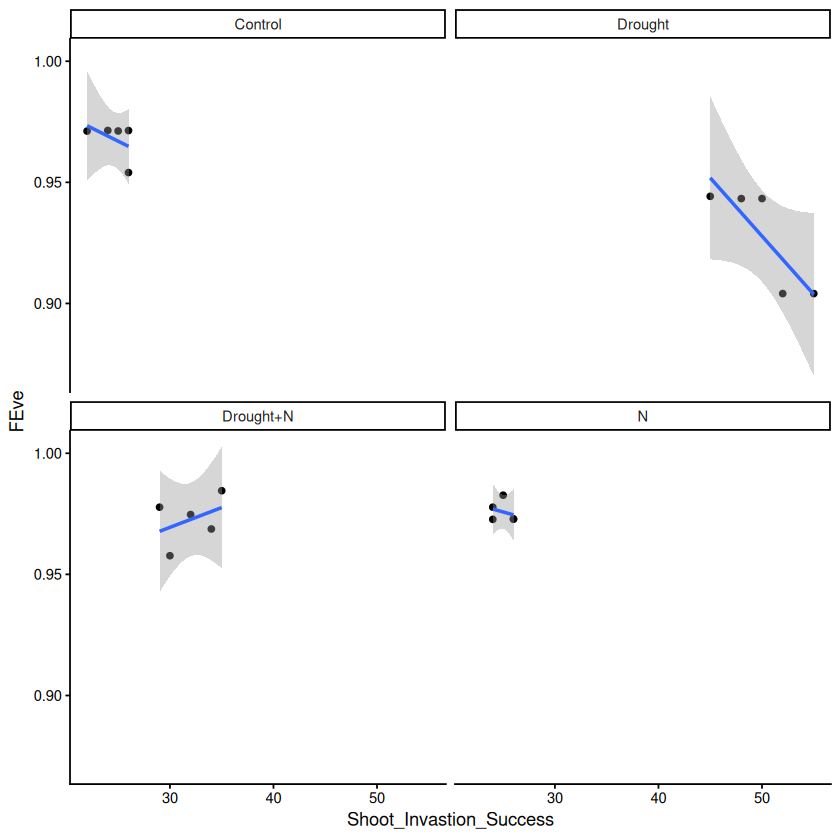

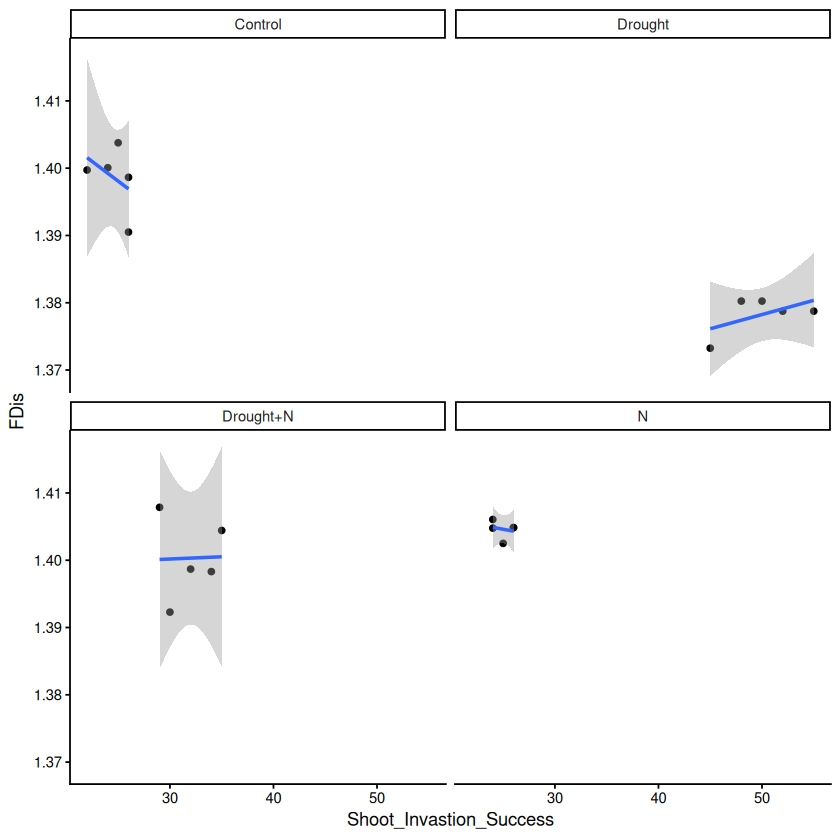

In [12]:
FEve_p <- ggplot(fd_full, aes(Shoot_Invastion_Success, FEve)) +
geom_point() +
geom_smooth(method = "lm") +
facet_wrap(~ Treatment) +
theme_classic()
FEve_p

FDis_p <- ggplot(fd_full, aes(Shoot_Invastion_Success, FDis)) +
geom_point() +
geom_smooth(method = "lm") +
facet_wrap(~ Treatment) +
theme_classic()
FDis_p

## 11. Plot for the CWM model results

`geom_smooth()` using formula = 'y ~ x'


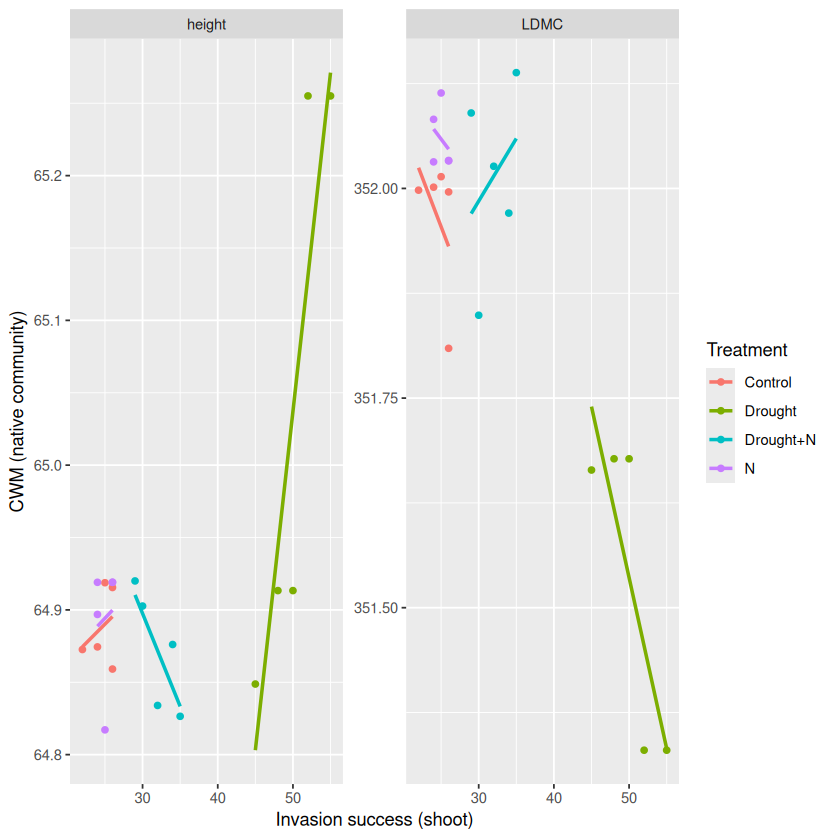

In [20]:
cwm_long <- cwm_full %>%
  pivot_longer(cols = c(SLA, LDMC, height),
               names_to = "trait",
               values_to = "CWM")

ggplot(cwm_long %>% filter(trait %in% c("LDMC", "height")),
       aes(x = Shoot_Invastion_Success,
           y = CWM,
           colour = Treatment)) +
  geom_point() +
  geom_smooth(method = "lm", se = FALSE) +
  facet_wrap(~ trait, scales = "free_y") +
  labs(x = "Invasion success (shoot)",
       y = "CWM (native community)")
